# Experiment 12: Project RESCUE-SWARM — Cooperative Multi-Agent Reinforcement Learning

**Aim:** Develop a small multi-agent reinforcement-learning system and compare independent Q-learning with a cooperative approach.

**Scenario:** A 7×7 disaster zone has two rescue agents (A and B), three victims (V), obstacles (#), and hazardous cells (H). Agents rescue a victim by moving onto its cell. The simulation is designed for teaching, not real-world emergency planning.

**Exercises covered:** environment design; states/actions/rewards; independent Q-learning; cooperative shared-information and shared-reward learning; visualizations and learning curves; quantitative evaluation.


## 1. Imports and reproducibility
We use NumPy and Matplotlib only. No dataset download is needed.

In [ ]:
import random
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

SEED = 12
random.seed(SEED)
np.random.seed(SEED)
print("Imports successful; seed =", SEED)


/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-cdcbglbq because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Imports successful; seed = 12


## 2. Environment design
The map includes safe cells, impassable obstacles, hazards, two agents, and three victims. The map is intentionally small so it can be explained in a viva.

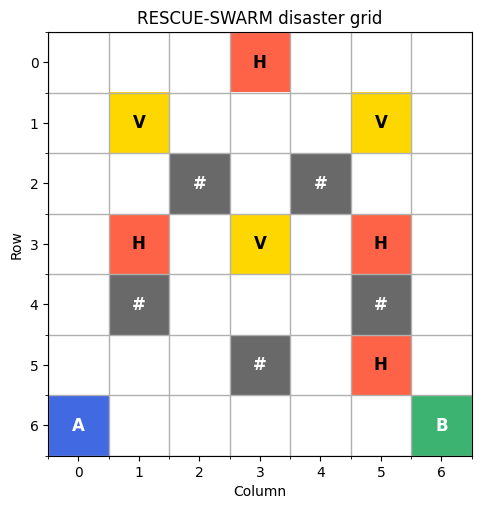

In [ ]:
N = 7
STARTS = [(6, 0), (6, 6)]
VICTIMS = [(1, 1), (1, 5), (3, 3)]
OBSTACLES = {(2, 2), (2, 4), (4, 1), (4, 5), (5, 3)}
HAZARDS = {(0, 3), (3, 1), (3, 5), (5, 5)}
ACTIONS = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1), 4: (0, 0)}
ACTION_NAMES = {0: "UP", 1: "DOWN", 2: "LEFT", 3: "RIGHT", 4: "WAIT"}

class RescueGrid:
    # A minimal gridworld for two rescue agents.
    def __init__(self, max_steps=45):
        self.max_steps = max_steps
        self.reset()

    def reset(self):
        self.positions = list(STARTS)
        self.victims_left = set(VICTIMS)
        self.steps = 0
        self.collisions = 0
        self.rescued_count = 0
        return self.observations()

    def observations(self):
        return [(self.positions[i], tuple(sorted(self.victims_left))) for i in range(2)]

    def step(self, actions):
        self.steps += 1
        old = list(self.positions)
        proposed = []
        for i, action in enumerate(actions):
            dr, dc = ACTIONS[int(action)]
            r, c = old[i]
            nxt = (r + dr, c + dc)
            if not (0 <= nxt[0] < N and 0 <= nxt[1] < N) or nxt in OBSTACLES:
                nxt = old[i]
            proposed.append(nxt)

        rewards = [-1.0, -1.0]  # time cost discourages unnecessary movement
        collision = proposed[0] == proposed[1] or (
            proposed[0] == old[1] and proposed[1] == old[0])
        if collision:
            self.collisions += 1
            rewards = [r - 5.0 for r in rewards]
            proposed = old[:]  # prevent overlapping positions

        self.positions = proposed
        for i, pos in enumerate(self.positions):
            if pos in HAZARDS:
                rewards[i] -= 4.0

        for victim in list(self.victims_left):
            rescuers = [i for i, pos in enumerate(self.positions) if pos == victim]
            if rescuers:
                winner = rescuers[0]
                self.victims_left.remove(victim)
                self.rescued_count += 1
                rewards[winner] += 20.0
                if len(rescuers) > 1:
                    rewards[1 - winner] += 5.0

        done = not self.victims_left or self.steps >= self.max_steps
        info = {"rescued": self.rescued_count, "remaining": len(self.victims_left),
                "steps": self.steps, "collisions": self.collisions,
                "all_rescued": not self.victims_left}
        return self.observations(), rewards, done, info

def draw_grid(env=None, title="RESCUE-SWARM disaster grid"):
    grid = np.zeros((N, N), dtype=int)
    for p in OBSTACLES: grid[p] = 1
    for p in HAZARDS: grid[p] = 2
    victims = VICTIMS if env is None else env.victims_left
    for p in victims: grid[p] = 3
    positions = STARTS if env is None else env.positions
    for i, p in enumerate(positions): grid[p] = 4 + i
    cmap = ListedColormap(["white", "dimgray", "tomato", "gold", "royalblue", "mediumseagreen"])
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.imshow(grid, cmap=cmap, vmin=0, vmax=5)
    labels = {1:"#", 2:"H", 3:"V", 4:"A", 5:"B"}
    for r in range(N):
        for c in range(N):
            if grid[r, c] in labels:
                ax.text(c, r, labels[grid[r,c]], ha="center", va="center",
                        color="white" if grid[r,c] in (1,4,5) else "black",
                        fontsize=12, fontweight="bold")
    ax.set_xticks(range(N)); ax.set_yticks(range(N))
    ax.set_xticks(np.arange(-.5, N, 1), minor=True)
    ax.set_yticks(np.arange(-.5, N, 1), minor=True)
    ax.grid(which="minor", linewidth=1)
    ax.set_title(title); ax.set_xlabel("Column"); ax.set_ylabel("Row")
    plt.show()

draw_grid()


## 3. States, actions, and rewards

**Actions:** up, down, left, right, or wait.

**Independent state:** `(own position, remaining victims)`.

**Cooperative state:** `(own position, teammate position, remaining victims)`. This extra information can help agents avoid duplicating effort.

**Rewards:** +20 for rescuing a victim; −1 per step; −4 for occupying a hazard; −5 per agent for a collision attempt. These are illustrative reward values, not universal settings.

## 4. Independent and cooperative Q-learning

The tabular update is `Q(s,a) ← Q(s,a) + α [r + γ max Q(s′,·) − Q(s,a)]`.

Independent agents learn from their own rewards and local state. Cooperative agents observe both positions and update from a shared team reward. Both methods use the same map, training episode count, and action set.

In [ ]:
ALPHA, GAMMA = 0.25, 0.95
TRAIN_EPISODES = 180

def state_ind(obs):
    return (obs[0], obs[1])

def state_coop(env, i):
    return (env.positions[i], env.positions[1-i], tuple(sorted(env.victims_left)))

def epsilon(ep, total):
    return 1.0 - 0.95 * ep / max(1, total-1)

def choose(q, s, eps):
    if random.random() < eps:
        return random.randrange(len(ACTIONS))
    vals = q[s]
    return int(random.choice(list(np.flatnonzero(vals == vals.max()))))

def update(q, s, a, r, ns, done):
    future = 0.0 if done else float(q[ns].max())
    q[s][a] += ALPHA * (r + GAMMA * future - q[s][a])

def train(cooperative, episodes=TRAIN_EPISODES):
    qs = [defaultdict(lambda: np.zeros(len(ACTIONS))) for _ in range(2)]
    hist = []
    for ep in range(episodes):
        env = RescueGrid()
        obs = env.reset()
        done = False
        total = 0.0
        eps = epsilon(ep, episodes)
        while not done:
            states = [state_coop(env, i) for i in range(2)] if cooperative else [state_ind(o) for o in obs]
            acts = [choose(qs[i], states[i], eps) for i in range(2)]
            next_obs, rewards, done, info = env.step(acts)
            next_states = [state_coop(env, i) for i in range(2)] if cooperative else [state_ind(o) for o in next_obs]
            reward_for_update = sum(rewards) if cooperative else None
            for i in range(2):
                reward = reward_for_update if cooperative else rewards[i]
                update(qs[i], states[i], acts[i], reward, next_states[i], done)
            total += sum(rewards)
            obs = next_obs
        hist.append({"reward": total, "rescued": info["rescued"], "steps": info["steps"],
                     "collisions": info["collisions"], "full": int(info["all_rescued"])})
    return qs, hist

print("Training independent Q-learning...")
ind_q, ind_hist = train(False)
print("Training cooperative Q-learning...")
coop_q, coop_hist = train(True)
print("Training completed:", len(ind_hist), "episodes per method.")


Training independent Q-learning...


Training cooperative Q-learning...


Training completed: 180 episodes per method.


## 5. Learning curves and rescue progress
Moving averages reduce episode-to-episode noise. Compare the trend, not a single episode.

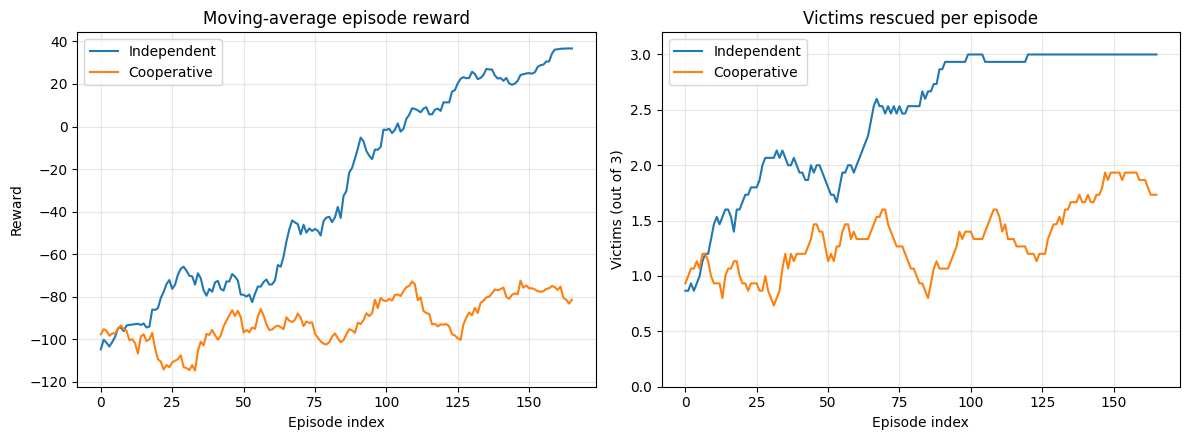

In [ ]:
def moving_avg(x, w=15):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w)/w, mode="valid") if len(x) >= w else x

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(moving_avg([h["reward"] for h in ind_hist]), label="Independent")
axes[0].plot(moving_avg([h["reward"] for h in coop_hist]), label="Cooperative")
axes[0].set_title("Moving-average episode reward"); axes[0].set_xlabel("Episode index")
axes[0].set_ylabel("Reward"); axes[0].grid(alpha=.3); axes[0].legend()
axes[1].plot(moving_avg([h["rescued"] for h in ind_hist]), label="Independent")
axes[1].plot(moving_avg([h["rescued"] for h in coop_hist]), label="Cooperative")
axes[1].set_title("Victims rescued per episode"); axes[1].set_xlabel("Episode index")
axes[1].set_ylabel("Victims (out of 3)"); axes[1].set_ylim(0, 3.2)
axes[1].grid(alpha=.3); axes[1].legend()
plt.tight_layout(); plt.show()


## 6. Performance evaluation

We evaluate with exploration turned off. Reported metrics are average victims rescued, full-rescue rate, episode steps, cumulative reward, and collisions. Results are measured from the trained policies; cooperation is not guaranteed to win in every small stochastic/learning setup.

INDEPENDENT Q-LEARNING
Average victims rescued / 3: 2.00
Full-rescue rate (%): 0.00
Average steps: 45.00
Average cumulative reward: -430.00
Average collisions: 38.00

COOPERATIVE Q-LEARNING
Average victims rescued / 3: 0.00
Full-rescue rate (%): 0.00
Average steps: 45.00
Average cumulative reward: -90.00
Average collisions: 0.00


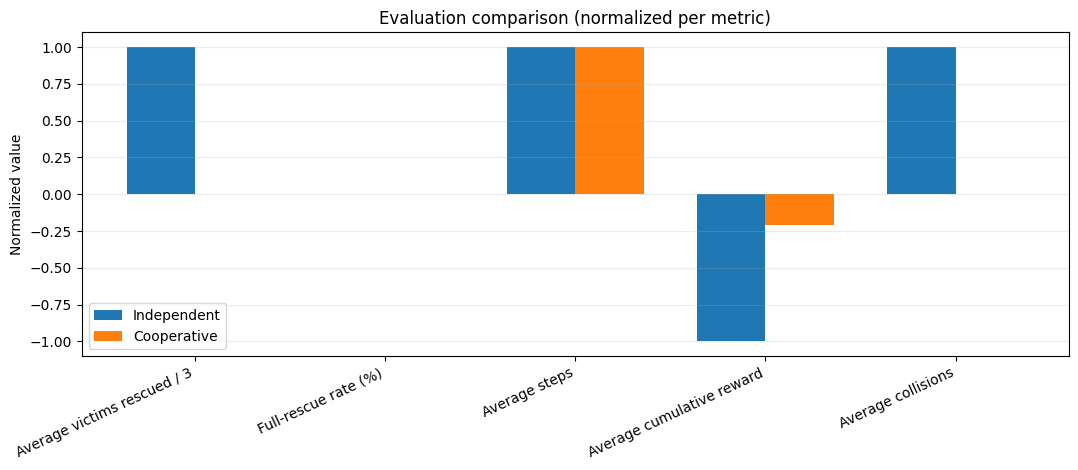

In [ ]:
def evaluate(qs, cooperative, episodes=60):
    rows = []
    for _ in range(episodes):
        env = RescueGrid()
        obs = env.reset()
        done = False
        total = 0.0
        while not done:
            states = [state_coop(env, i) for i in range(2)] if cooperative else [state_ind(o) for o in obs]
            acts = [choose(qs[i], states[i], 0.0) for i in range(2)]
            obs, rewards, done, info = env.step(acts)
            total += sum(rewards)
        rows.append({"rescued": info["rescued"], "full": info["all_rescued"],
                     "steps": info["steps"], "reward": total, "collisions": info["collisions"]})
    return rows

ind_eval = evaluate(ind_q, False)
coop_eval = evaluate(coop_q, True)

def summarize(rows):
    return {
        "Average victims rescued / 3": np.mean([x["rescued"] for x in rows]),
        "Full-rescue rate (%)": 100*np.mean([x["full"] for x in rows]),
        "Average steps": np.mean([x["steps"] for x in rows]),
        "Average cumulative reward": np.mean([x["reward"] for x in rows]),
        "Average collisions": np.mean([x["collisions"] for x in rows])
    }

ind_summary, coop_summary = summarize(ind_eval), summarize(coop_eval)
print("INDEPENDENT Q-LEARNING")
for k, v in ind_summary.items(): print(f"{k}: {v:.2f}")
print("\nCOOPERATIVE Q-LEARNING")
for k, v in coop_summary.items(): print(f"{k}: {v:.2f}")

keys = list(ind_summary)
x = np.arange(len(keys)); width = .36
# Normalize per metric for a readable comparison despite different units.
a, b = [], []
for k in keys:
    scale = max(abs(ind_summary[k]), abs(coop_summary[k]), 1e-9)
    a.append(ind_summary[k]/scale); b.append(coop_summary[k]/scale)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(x-width/2, a, width, label="Independent")
ax.bar(x+width/2, b, width, label="Cooperative")
ax.set_xticks(x); ax.set_xticklabels(keys, rotation=25, ha="right")
ax.set_ylabel("Normalized value"); ax.set_title("Evaluation comparison (normalized per metric)")
ax.legend(); ax.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()


## 7. Example movement snapshots
This shows the cooperative greedy policy for a few steps. It provides a visual example without creating a large animation.

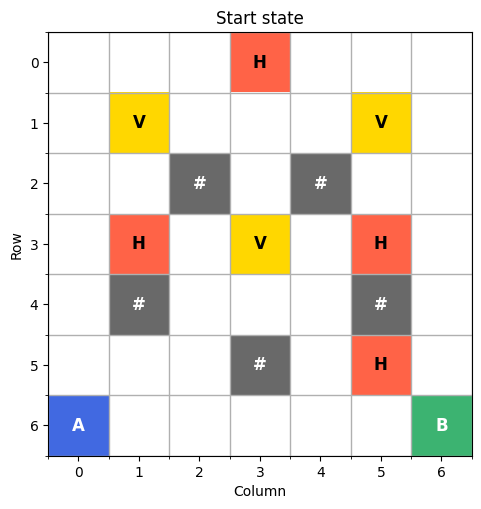

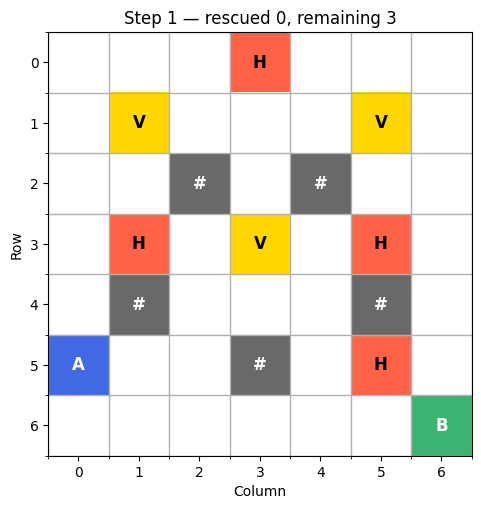

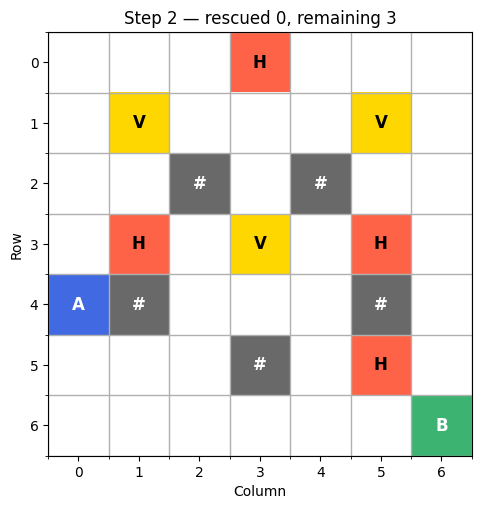

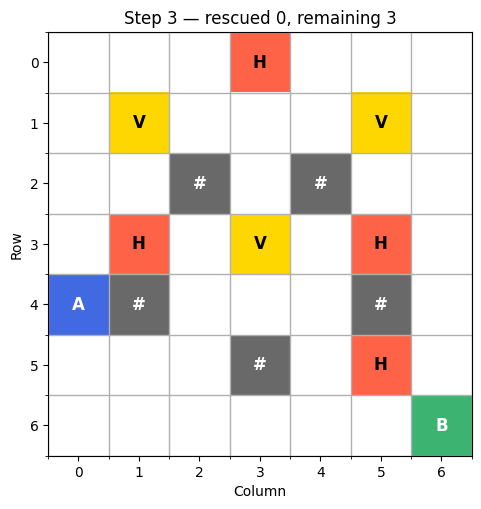

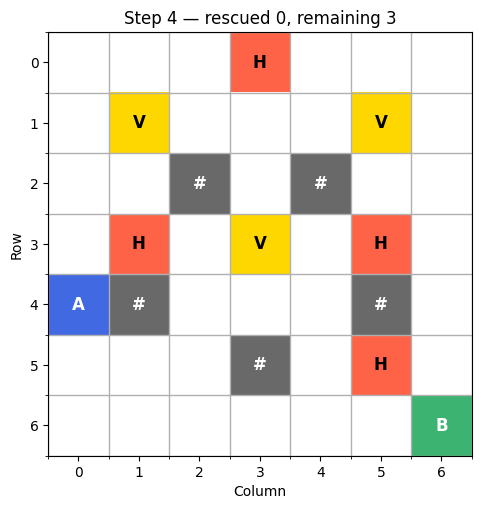

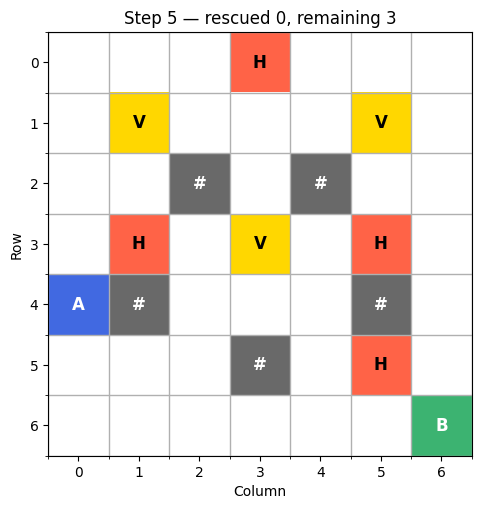

Demo result: {'rescued': 0, 'remaining': 3, 'steps': 5, 'collisions': 0, 'all_rescued': False}


In [ ]:
def demo(qs, cooperative=True, max_steps=6):
    env = RescueGrid()
    obs = env.reset()
    draw_grid(env, "Start state")
    for _ in range(max_steps):
        states = [state_coop(env, i) for i in range(2)] if cooperative else [state_ind(o) for o in obs]
        acts = [choose(qs[i], states[i], 0.0) for i in range(2)]
        obs, rewards, done, info = env.step(acts)
        draw_grid(env, f"Step {info['steps']} — rescued {info['rescued']}, remaining {info['remaining']}")
        if done: break
    print("Demo result:", info)

demo(coop_q, cooperative=True, max_steps=5)


## 8. Recent training samples

These examples show why the evaluation should use many episodes rather than selecting one successful or unsuccessful run.

In [ ]:
def show_recent(history, name, n=8):
    print("\n" + name + " — last", n, "training episodes")
    print("Episode | Reward | Rescued | Steps | Collisions")
    start = max(1, len(history)-n+1)
    for i, h in enumerate(history[-n:], start=start):
        print(f"{i:7d} | {h['reward']:6.1f} | {h['rescued']:7d} | {h['steps']:5d} | {h['collisions']:10d}")

show_recent(ind_hist, "Independent")
show_recent(coop_hist, "Cooperative")



Independent — last 8 training episodes
Episode | Reward | Rescued | Steps | Collisions
    173 |   40.0 |       3 |    10 |          0
    174 |   40.0 |       3 |    10 |          0
    175 |   40.0 |       3 |    10 |          0
    176 |   40.0 |       3 |    10 |          0
    177 |   40.0 |       3 |    10 |          0
    178 |   40.0 |       3 |    10 |          0
    179 |   40.0 |       3 |    10 |          0
    180 |   36.0 |       3 |    12 |          0

Cooperative — last 8 training episodes
Episode | Reward | Rescued | Steps | Collisions
    173 |  -66.0 |       2 |    45 |          0
    174 |  -58.0 |       2 |    45 |          0
    175 | -118.0 |       1 |    45 |          0
    176 |  -74.0 |       2 |    45 |          0
    177 |  -90.0 |       2 |    45 |          0
    178 |  -86.0 |       1 |    45 |          0
    179 |  -86.0 |       2 |    45 |          0
    180 |  -58.0 |       2 |    45 |          0


## 9. Conclusion and viva questions

### Conclusion
- Gridworld states, actions, and rewards can model a simplified rescue task.
- Q-learning learns action values from reward feedback.
- Independent agents may duplicate effort because they do not directly optimize a shared objective.
- Shared information and a team reward encourage coordination, but do not guarantee better performance.
- Compare rescue count, full-rescue rate, steps, reward, and collisions together.

### Viva questions
1. **Why use a step penalty?** To discourage wandering and favor shorter routes.
2. **Why penalize hazards?** To make dangerous cells less attractive.
3. **How do the two methods differ?** Independent agents use local states and individual rewards; cooperative agents use both positions and shared team reward.
4. **Why are learning curves noisy?** Exploration and the other agent's changing behavior affect outcomes.
5. **Is cooperation always better?** No; results depend on reward design, state representation, and training.
6. **How could it be extended?** More random seeds, dynamic hazards, communication limits, action masking, centralized critics, QMIX, or MADDPG.

**Limitation:** This is an educational toy model, not a real-world evacuation or emergency-response system.
